## Q1. Handling Missing Values and Data Type

The `delivery_time_mins` column has 14% missing values. I would prefer imputation instead of dropping rows because 14% is a significant amount of data and dropping these rows can remove useful information.

If the delivery time data is skewed, I would use the median because the median is less affected by extreme values. If the data is approximately normally distributed, the mean can be used.

For the `customer_rating` column, string values such as '4.5' should be converted into numeric values before analysis.

In [1]:
# Import Pandas
import pandas as pd

In [2]:
# Example data
# Some delivery times are missing
# Customer ratings are stored as strings

data = {
    'delivery_time_mins': [25, 30, 35, None, 45, 50, None, 40],
    'customer_rating': ['4.5', '4.0', '3.5', '4.2', '5.0', '3.8', '4.6', '4.1']
}

df = pd.DataFrame(data)

# Display the data
df

,delivery_time_mins,customer_rating
0,25.0,4.5
1,30.0,4.0
2,35.0,3.5
3,NaN,4.2
4,45.0,5.0
5,50.0,3.8
6,NaN,4.6
7,40.0,4.1


In [3]:
# Check the data types of the columns

print(df.dtypes)

delivery_time_mins    float64
customer_rating        object
dtype: object


In [5]:
# Check missing values before cleaning

print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
delivery_time_mins    2
customer_rating       0
dtype: int64


In [6]:
# Convert customer_rating from string/object to numeric
# Invalid values will be converted to NaN

df['customer_rating'] = pd.to_numeric(
    df['customer_rating'],
    errors='coerce'
)

# Check data types after conversion
print(df.dtypes)

delivery_time_mins    float64
customer_rating       float64
dtype: object


In [7]:
# Fill missing delivery time values using the median
# Median is useful when the data is skewed

median_delivery_time = df['delivery_time_mins'].median()

df['delivery_time_mins'] = df['delivery_time_mins'].fillna(
    median_delivery_time
)

# Display cleaned data
df

,delivery_time_mins,customer_rating
0,25.0,4.5
1,30.0,4.0
2,35.0,3.5
3,37.5,4.2
4,45.0,5.0
5,50.0,3.8
6,37.5,4.6
7,40.0,4.1


In [8]:
# Check missing values after cleaning

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nFinal data types:")
print(df.dtypes)

Missing values after cleaning:
delivery_time_mins    0
customer_rating       0
dtype: int64

Final data types:
delivery_time_mins    float64
customer_rating       float64
dtype: object


## Q2. NumPy Boolean Indexing and Statistical Functions

`np.mean()` calculates the average order count and `np.std()` calculates the standard deviation.

A surge day is identified when the order count is greater than:

mean + 1.5 × standard deviation

NumPy Boolean indexing creates a True/False mask. The same mask can be applied to the revenue array to select the revenue of only the surge days.

NumPy vectorized operations are preferred over Python loops because they perform operations on the whole array at once and make the code shorter and generally faster.

In [9]:
# Import NumPy
import numpy as np

In [10]:
# Daily order counts for 30 days

orders = np.array([
    120, 150, 180, 200, 220, 250, 190, 300, 280, 350,
    400, 210, 230, 270, 320, 450, 200, 240, 290, 310,
    500, 260, 280, 330, 370, 420, 190, 220, 600, 250
])

# Matching revenue for each day

revenue = np.array([
    6000, 7000, 8000, 9000, 10000, 11000, 8500, 13000, 12000, 15000,
    17000, 9000, 10000, 11500, 14000, 19000, 8500, 10500, 12500, 13500,
    21000, 11000, 12000, 14500, 16000, 18000, 8500, 9500, 25000, 11000
])

print("Order counts:")
print(orders)

print("\nRevenue:")
print(revenue)

Order counts:
[120 150 180 200 220 250 190 300 280 350 400 210 230 270 320 450 200 240
 290 310 500 260 280 330 370 420 190 220 600 250]

Revenue:
[ 6000  7000  8000  9000 10000 11000  8500 13000 12000 15000 17000  9000
 10000 11500 14000 19000  8500 10500 12500 13500 21000 11000 12000 14500
 16000 18000  8500  9500 25000 11000]


In [11]:
# Calculate mean order count

mean_orders = np.mean(orders)

# Calculate standard deviation

std_orders = np.std(orders)

print("Mean order count:", mean_orders)
print("Standard deviation:", std_orders)

Mean order count: 286.0
Standard deviation: 105.05871374299865


In [12]:
# Calculate the surge-day threshold
# Surge day = order count > mean + 1.5 * standard deviation

threshold = mean_orders + 1.5 * std_orders

print("Surge-day threshold:", threshold)

Surge-day threshold: 443.58807061449795


In [13]:
# Create a Boolean mask
# True means the day is a surge day
# False means it is not a surge day

surge_mask = orders > threshold

print("Boolean mask:")
print(surge_mask)

Boolean mask:
[False False False False False False False False False False False False
 False False False  True False False False False  True False False False
 False False False False  True False]


In [14]:
# Use Boolean indexing to select surge-day orders

surge_orders = orders[surge_mask]

# Use the same Boolean mask to select matching revenue

surge_revenue = revenue[surge_mask]

print("Surge-day orders:")
print(surge_orders)

print("\nRevenue on surge days:")
print(surge_revenue)

Surge-day orders:
[450 500 600]

Revenue on surge days:
[19000 21000 25000]


In [15]:
# Calculate total revenue from surge days

total_surge_revenue = np.sum(surge_revenue)

print("Total revenue from surge days:", total_surge_revenue)

Total revenue from surge days: 65000


## Q3. Exploratory Data Analysis

### (a) Delivery Time and Customer Rating

This is Bivariate Analysis because it studies the relationship between two variables:
- `delivery_time_mins`
- `customer_rating`

A Seaborn scatter plot is suitable because it shows the relationship between two numerical variables.

### (b) Average Order Value Across Restaurant Categories

This is Bivariate Analysis because it compares:
- `restaurant_category`
- `average_order_value`

A Seaborn box plot is suitable because it compares the distribution of order values across different restaurant categories and can also show spread and outliers.

A simple line plot is not suitable because the questions do not represent a continuous time sequence.

In [16]:
# Import Seaborn and Matplotlib

import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
# Example EDA dataset

eda_data = {
    'restaurant_category': [
        'Indian', 'Chinese', 'Italian', 'Indian',
        'Chinese', 'Italian', 'Indian', 'Chinese',
        'Italian', 'Indian'
    ],
    
    'average_order_value': [
        350, 420, 550, 380, 450,
        600, 320, 480, 520, 400
    ],
    
    'customer_rating': [
        4.5, 4.0, 3.8, 4.6, 3.9,
        4.2, 4.7, 3.7, 4.1, 4.4
    ],
    
    'delivery_time_mins': [
        30, 40, 45, 28, 42,
        50, 25, 44, 48, 32
    ]
}

eda_df = pd.DataFrame(eda_data)

eda_df

,restaurant_category,average_order_value,customer_rating,delivery_time_mins
0,Indian,350,4.5,30
1,Chinese,420,4.0,40
2,Italian,550,3.8,45
3,Indian,380,4.6,28
4,Chinese,450,3.9,42
5,Italian,600,4.2,50
6,Indian,320,4.7,25
7,Chinese,480,3.7,44
8,Italian,520,4.1,48
9,Indian,400,4.4,32


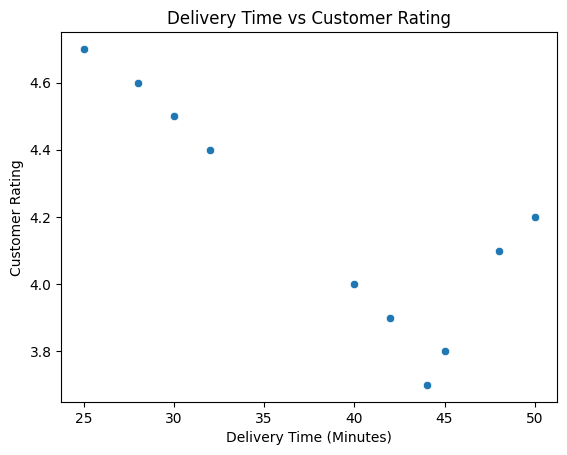

In [18]:
# Scatter plot:
# Shows the relationship between delivery time and customer rating

sns.scatterplot(
    data=eda_df,
    x='delivery_time_mins',
    y='customer_rating'
)

plt.title('Delivery Time vs Customer Rating')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Customer Rating')

plt.show()

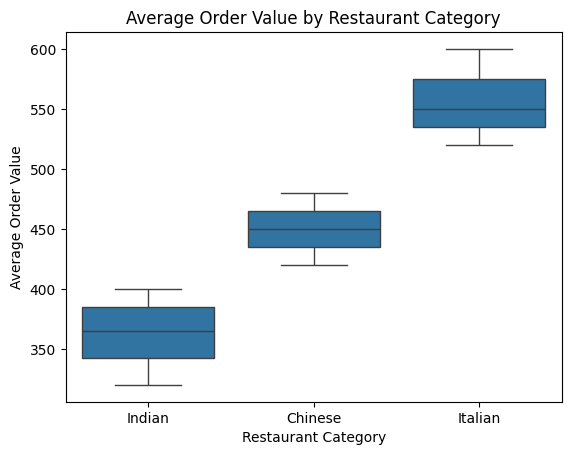

In [19]:
# Box plot:
# Shows the distribution of average order value
# for each restaurant category

sns.boxplot(
    data=eda_df,
    x='restaurant_category',
    y='average_order_value'
)

plt.title('Average Order Value by Restaurant Category')
plt.xlabel('Restaurant Category')
plt.ylabel('Average Order Value')

plt.show()